# Week 7 - Statistical Business Analysis

**Goal:** use statistics to find what drives customer churn and order value, and turn the findings into business recommendations.

| Step | What we do |
|---|---|
| 1 | Descriptive statistics (mean, median, mode, SD, variance, quartiles, skewness, kurtosis) |
| 2 | Distribution analysis - histograms with KDE, Q-Q plots, Shapiro-Wilk and D'Agostino tests |
| 3 | Correlation analysis - Pearson and Spearman with p-values and a heatmap |
| 4 | Hypothesis testing - 6 tests (Welch t-test, chi-square, ANOVA) with non-parametric checks |
| 5 | Confidence intervals - t, Wilson and bootstrap 95% CIs with margins of error |
| 6 | Regression analysis - OLS with R-squared, coefficients, p-values and residual diagnostics |
| 7 | Business insights and recommendations |

**Data**
- `business_data.csv` - 500 customers (Tenure, MonthlyCharges, TotalCharges, Contract, PaymentMethod, PaperlessBilling, SeniorCitizen, Churn)
- `data/sales_data.csv` - 100 orders (Product, Quantity, Price, Region, Total_Sales)

> **Scope note:** neither dataset contains marketing spend, so the "marketing spend vs revenue" example in the task brief cannot be tested. The same techniques are applied to the relationships that do exist in the data.

All reusable logic lives in `stats_analysis.py`; this notebook calls it step by step and explains the results.

In [1]:
import warnings
import pandas as pd
from IPython.display import Image, display

import stats_analysis as sa

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 120)
ALPHA = sa.ALPHA

## 0. Load and validate the data

In [2]:
biz = sa.load_business_data()
sales = sa.load_sales_data()
print(f"Business data: {biz.shape[0]} rows x {biz.shape[1]} columns, missing values: {int(biz.isna().sum().sum())}")
print(f"Sales data   : {sales.shape[0]} rows x {sales.shape[1]} columns, missing values: {int(sales.isna().sum().sum())}")
print(f"Churn rate   : {biz['Churn'].mean():.1%} ({int(biz['Churn'].sum())} of {len(biz)} customers)")
biz.head()

Business data: 500 rows x 10 columns, missing values: 0
Sales data   : 100 rows x 7 columns, missing values: 0
Churn rate   : 10.6% (53 of 500 customers)


,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn,Status
0,C00001,6,64,1540,One year,Credit Card,No,1,0,Retained
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0,Retained
2,C00003,27,31,1455,Two year,Credit Card,No,1,0,Retained
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0,Retained
4,C00005,16,185,1023,One year,Electronic Check,No,1,0,Retained


### Data-quality check: is TotalCharges consistent?
If `TotalCharges` were the running total a customer has paid, it should be close to `Tenure x MonthlyCharges`. We check this before using the column.

In [3]:
quality, ratio = sa.total_charges_consistency(biz)
quality

{'rows': 500,
 'within_tolerance': 32,
 'pct_within_tolerance': np.float64(6.4),
 'median_ratio': 1.133,
 'min_ratio': 0.019,
 'max_ratio': 208.067,
 'corr_total_vs_expected': -0.037}

**Finding:** only a small share of rows are within 10% of the expected value and the correlation is about zero, so `TotalCharges` does not behave like a running total. We report this as a data-quality issue and do not base any business conclusion on `TotalCharges`.

## 1. Descriptive statistics

In [4]:
desc_biz = sa.descriptive_stats(biz, sa.BUSINESS_NUMERIC)
desc_sales = sa.descriptive_stats(sales, sa.SALES_NUMERIC)
display(desc_biz.round(2))
display(desc_sales.round(2))

,count,mean,median,mode,std,variance,min,q1,q3,iqr,max,skewness,kurtosis,cv_%
Tenure,500.0000,36.5300,37.0000,3.0000,20.6700,427.1300,1.0000,19.0000,54.0000,35.0000,71.0000,-0.0900,-1.2200,56.5700
MonthlyCharges,500.0000,113.6400,115.0000,115.0000,51.8000,"2,683.2300",20.0000,67.0000,158.0000,91.0000,199.0000,-0.0900,-1.2100,45.5800
TotalCharges,500.0000,"4,237.8800","4,182.5000","4,023.0000","2,260.6200","5,110,402.0500",159.0000,"2,237.2500","6,266.7500","4,029.5000","7,992.0000",-0.0300,-1.2200,53.3400


,count,mean,median,mode,std,variance,min,q1,q3,iqr,max,skewness,kurtosis,cv_%
Quantity,100.0000,4.7800,5.0000,4.0000,2.5900,6.7000,1.0000,2.7500,7.0000,4.2500,9.0000,0.0700,-1.2000,54.1500
Price,100.0000,"25,808.5100","24,192.0000","1,308.0000","13,917.6300","193,700,431.5500","1,308.0000","14,965.2500","38,682.2500","23,717.0000","49,930.0000",-0.0100,-1.2600,53.9300
Total_Sales,100.0000,"123,650.4800","97,955.5000","6,540.0000","100,161.0900","10,032,243,003.4600","6,540.0000","39,517.5000","175,792.5000","136,275.0000","373,932.0000",0.8800,-0.1800,81.0000


**Reading the table**
- Tenure, MonthlyCharges and TotalCharges have mean = median and negative kurtosis: they are spread almost evenly across their range (flat, not bell-shaped).
- Total_Sales has mean > median and positive skew: a few large orders pull the average up.

## 2. Distribution analysis and normality tests

In [5]:
normality = pd.concat([sa.normality_tests(biz, sa.BUSINESS_NUMERIC), sa.normality_tests(sales, ["Total_Sales"])])
normality

,shapiro_W,shapiro_p,dagostino_K2,dagostino_p,normal_at_5%
variable,,,,,
Tenure,0.9496,0.0000,356.2050,0.0000,False
MonthlyCharges,0.9520,0.0000,348.8008,0.0000,False
TotalCharges,0.9514,0.0000,377.7135,0.0000,False
Total_Sales,0.8989,0.0000,11.2433,0.0036,False


All p-values are far below 0.05, so **none of the variables is normally distributed**. That is why every parametric test below (t-test, ANOVA) is paired with a non-parametric check (Mann-Whitney U, Kruskal-Wallis). With 500 customers the t-test is still reliable thanks to the Central Limit Theorem.

## 3. Correlation analysis

In [6]:
pearson = pd.concat([sa.correlation_table(biz, sa.BUSINESS_NUMERIC + ["Churn"]),
                     sa.correlation_table(sales, sa.SALES_NUMERIC)], ignore_index=True)
spearman = pd.concat([sa.correlation_table(biz, sa.BUSINESS_NUMERIC + ["Churn"], "spearman"),
                      sa.correlation_table(sales, sa.SALES_NUMERIC, "spearman")], ignore_index=True)
display(pearson.round(4))
display(spearman[["var_1", "var_2", "r", "p_value"]].rename(columns={"r": "rho"}).round(4))

,var_1,var_2,r,p_value,strength,significant
0,Tenure,MonthlyCharges,-0.0597,0.1829,negligible,False
1,Tenure,TotalCharges,-0.0057,0.8992,negligible,False
2,Tenure,Churn,-0.5092,0.0000,moderate,True
3,MonthlyCharges,TotalCharges,-0.0423,0.3454,negligible,False
4,MonthlyCharges,Churn,0.1074,0.0163,negligible,True
5,TotalCharges,Churn,0.0042,0.9245,negligible,False
6,Quantity,Price,0.0080,0.9369,negligible,False
7,Quantity,Total_Sales,0.6881,0.0000,moderate,True
8,Price,Total_Sales,0.6461,0.0000,moderate,True


,var_1,var_2,rho,p_value
0,Tenure,MonthlyCharges,-0.0620,0.1663
1,Tenure,TotalCharges,-0.0065,0.8846
2,Tenure,Churn,-0.4951,0.0000
3,MonthlyCharges,TotalCharges,-0.0402,0.3700
4,MonthlyCharges,Churn,0.1057,0.0181
5,TotalCharges,Churn,0.0046,0.9180
6,Quantity,Price,0.0109,0.9145
7,Quantity,Total_Sales,0.6914,0.0000
8,Price,Total_Sales,0.6798,0.0000


- **Tenure vs Churn: r = -0.51 (moderate, p < 0.001)** - longer-tenure customers are much less likely to churn.
- MonthlyCharges vs Churn is statistically significant but very weak (r = 0.11).
- In the sales data, Quantity and Price each correlate moderately with Total_Sales but not with each other (r = 0.01), so customers do not buy fewer units of expensive items.
- Spearman (rank) correlations give the same picture, so the results are not driven by outliers.

## 4. Hypothesis testing
Significance level alpha = 0.05 for every test. Each result shows H0, H1, the test statistic, p-value, effect size and conclusion.

In [7]:
tests = sa.run_hypothesis_tests(biz, sales)
summary = pd.DataFrame([{
    "test": r.name, "method": r.test, "statistic": r.statistic, "p_value": r.p_value,
    "effect": f"{r.effect_label} = {r.effect_size:.3f}", "decision": "Reject H0" if r.reject_h0 else "Fail to reject H0",
} for r in tests])
summary

,test,method,statistic,p_value,effect,decision
0,T1: Do churned customers have shorter tenure?,Welch two-sample t-test,-34.5349,0.0000,Cohen's d = -1.918,Reject H0
1,T2: Do churned customers pay higher monthly ch...,Welch two-sample t-test,2.6464,0.0101,Cohen's d = 0.350,Reject H0
2,T3: Is churn related to contract type?,Chi-square test of independence,27.7153,0.0000,Cramer's V = 0.235,Reject H0
3,T4: Is churn related to payment method?,Chi-square test of independence,3.8695,0.1445,Cramer's V = 0.088,Fail to reject H0
4,T5: Do monthly charges differ by contract type?,One-way ANOVA,0.0313,0.9692,eta squared = 0.000,Fail to reject H0
5,T6: Does order value differ by product?,One-way ANOVA,2.0508,0.0934,eta squared = 0.079,Fail to reject H0


In [8]:
for r in tests:
    print(r.name)
    print(f"  H0: {r.h0}\n  H1: {r.h1}")
    print(f"  {r.conclusion}\n")

T1: Do churned customers have shorter tenure?
  H0: Mean Tenure is the same for Churned and Retained customers
  H1: Mean Tenure differs between Churned and Retained customers
  Reject H0. Mean Tenure is 6.0 for Churned vs 40.2 for Retained (difference -34.2); effect size is large. Mann-Whitney U agrees (p = 2.00e-28).

T2: Do churned customers pay higher monthly charges?
  H0: Mean MonthlyCharges is the same for Churned and Retained customers
  H1: Mean MonthlyCharges differs between Churned and Retained customers
  Reject H0. Mean MonthlyCharges is 129.8 for Churned vs 111.7 for Retained (difference +18.1); effect size is small. Mann-Whitney U agrees (p = 0.0183).

T3: Is churn related to contract type?
  H0: Contract and Churn are independent
  H1: Contract and Churn are associated
  Reject H0. Contract and Churn are associated (Cramer's V = 0.24, small). Churn rate: Month-to-month 20.6%, One year 4.3%, Two year 6.9%.

T4: Is churn related to payment method?
  H0: PaymentMethod and 

### Multiple-testing check
Running 6 tests raises the chance of a false positive, so we also apply a Bonferroni correction.

In [9]:
threshold, survivors = sa.bonferroni(tests)
print(f"Bonferroni threshold: {threshold:.4f}")
print("Still significant:", ", ".join(s[:2] for s in survivors))

Bonferroni threshold: 0.0083
Still significant: T1, T3


**What the tests tell us**
- **T1 (tenure):** churned customers averaged about 6 months vs about 40 for retained - a very large effect. No customer churned after 11 months.
- **T3 (contract):** churn depends on contract type; month-to-month customers churn far more.
- **T2 (monthly charges):** churned customers pay a bit more, but this small effect is not significant after the Bonferroni correction - treat it as a lead to investigate, not a fact.
- **T4, T5, T6:** payment method, pricing by contract and product category show no significant effect.

In [10]:
print("Customers with tenure <= 12 months, by contract type")
display(sa.short_tenure_contract_table(biz))

Customers with tenure <= 12 months, by contract type


Status,Churned,Retained
Contract,,
Month-to-month,35,0
One year,8,18
Two year,10,13


## 5. Confidence intervals and margin of error

In [11]:
cis = sa.key_confidence_intervals(biz, sales)
ci_table = pd.DataFrame(cis).T[["estimate", "lower", "upper", "margin_of_error", "n", "method"]]
ci_table

,estimate,lower,upper,margin_of_error,n,method
Mean monthly charges,113.6360,109.0846,118.1874,4.5514,500,t
Mean tenure (months),36.5320,34.7161,38.3479,1.8159,500,t
Churn rate,0.1060,0.0820,0.1361,0.0270,500,Wilson
Mean order value (t),"123,650.4800","103,776.3477","143,524.6123","19,874.1323",100,t
Mean order value (bootstrap),"123,650.4800","104,514.8430","143,763.0560","19,624.1065",100,"bootstrap (10,000 resamples)"
Median order value (bootstrap),"97,955.5000","73,941.4875","135,980.0000","31,019.2562",100,"bootstrap (10,000 resamples)"


- We are 95% confident the true average monthly charge is between about 109 and 118.
- The churn rate is 10.6% with a Wilson 95% CI of about 8.2%-13.6% (Wilson works better than the normal approximation for proportions near 0).
- For order value, the t-interval and the bootstrap interval almost match, which confirms the t-interval is fine even though order values are skewed.

## 6. Regression analysis

In [12]:
models = sa.run_regressions(biz, sales)
for key, model in models.items():
    s = sa.regression_summary(model)
    print(f"{s['formula']}:  R^2 = {s['r_squared']:.4f}, adj R^2 = {s['adj_r_squared']:.4f}, F-test p = {sa.fmt_p(s['f_pvalue'])}")
    display(s["coefficients"].round(4))

Total_Sales ~ Quantity + Price:  R^2 = 0.8839, adj R^2 = 0.8815, F-test p = 4.40e-46


,coef,std_err,t,p_value,ci_low,ci_high
Intercept,"-121,682.2174","9,668.2939",-12.5857,0.0000,"-140,871.1045","-102,493.3303"
Quantity,"26,430.8402","1,338.8686",19.7412,0.0000,"23,773.5566","29,088.1238"
Price,4.6106,0.2490,18.5181,0.0000,4.1165,5.1048


log_total ~ log_qty + log_price:  R^2 = 1.0000, adj R^2 = 1.0000, F-test p = < 1e-300


,coef,std_err,t,p_value,ci_low,ci_high
Intercept,0.0000,0.0000,0.2732,0.7853,-0.0000,0.0000
log_qty,1.0000,0.0000,"804,815,378,171,296.7500",0.0000,1.0000,1.0000
log_price,1.0000,0.0000,"868,612,065,987,899.2500",0.0000,1.0000,1.0000


TotalCharges ~ Tenure + MonthlyCharges:  R^2 = 0.0019, adj R^2 = -0.0022, F-test p = 0.6304


,coef,std_err,t,p_value,ci_low,ci_high
Intercept,"4,482.8713",311.0645,14.4114,0.0000,"3,871.7078","5,094.0348"
Tenure,-0.9000,4.9107,-0.1833,0.8547,-10.5483,8.7482
MonthlyCharges,-1.8666,1.9593,-0.9527,0.3412,-5.7160,1.9829


- **Total_Sales ~ Quantity + Price:** R-squared = 0.884. Both predictors are highly significant. The residual plot (below) is U-shaped because order value is really `Quantity x Price`; the log-log model captures this exactly (R-squared = 1, both coefficients = 1).
- **TotalCharges ~ Tenure + MonthlyCharges:** R-squared is about 0 - this confirms the data-quality issue found earlier.

## 7. Visualizations
Running the full pipeline regenerates every chart, `hypothesis_tests_results.txt` and `statistical_report.pdf`.

INFO: Loaded 500 customers and 100 orders


INFO: Wrote hypothesis_tests_results.txt, statistical_report.pdf and 9 charts


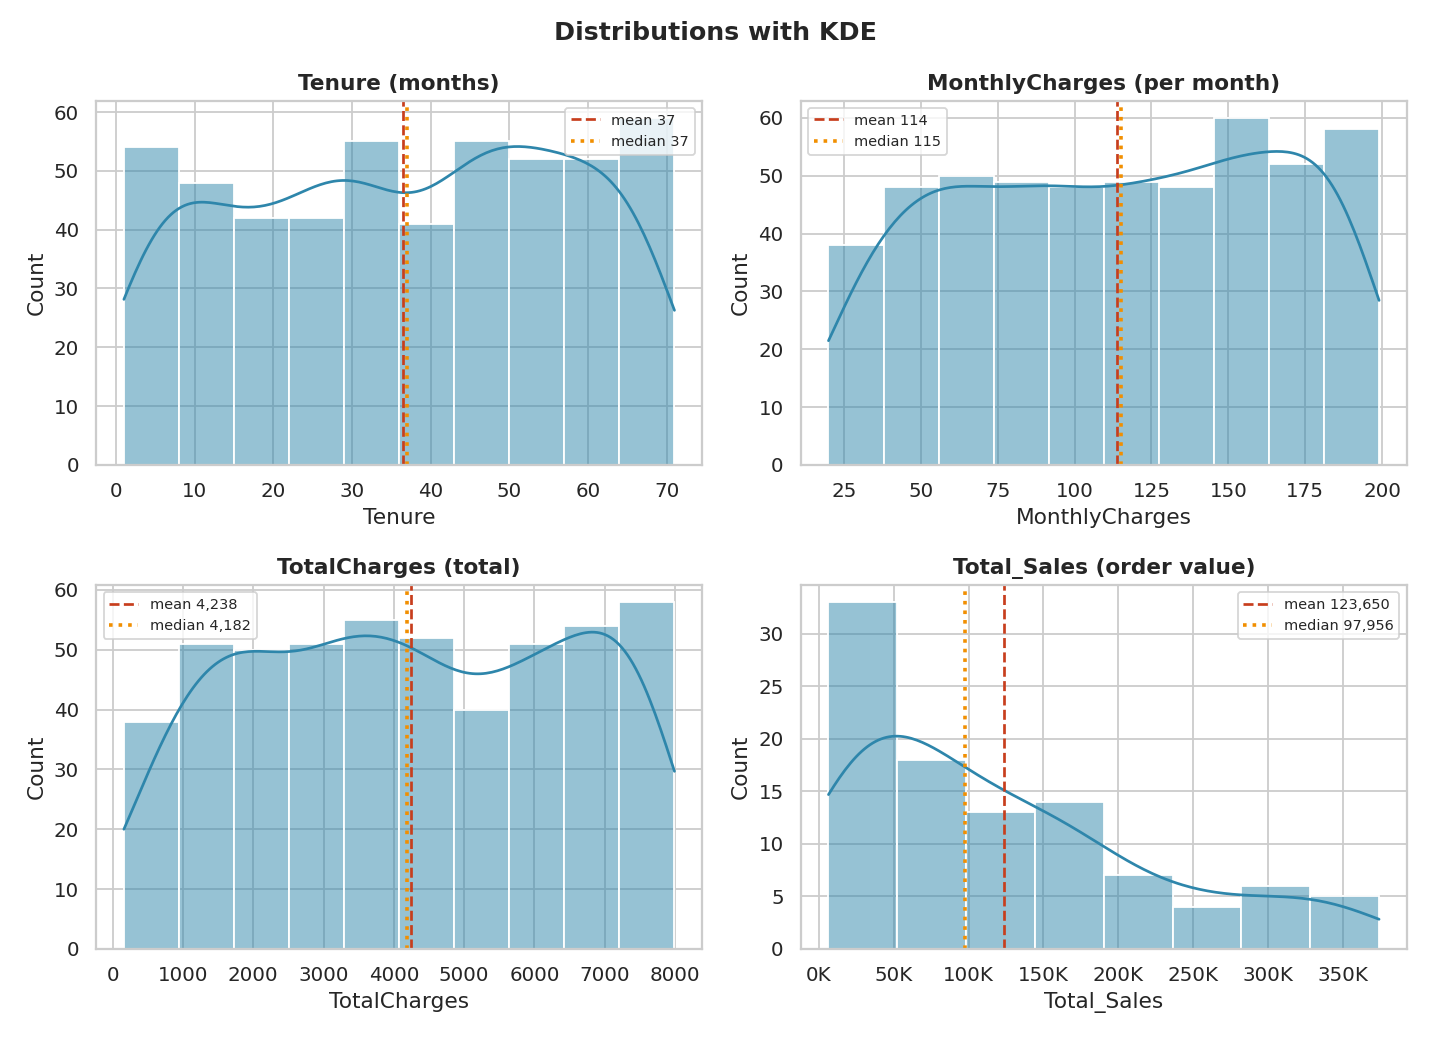

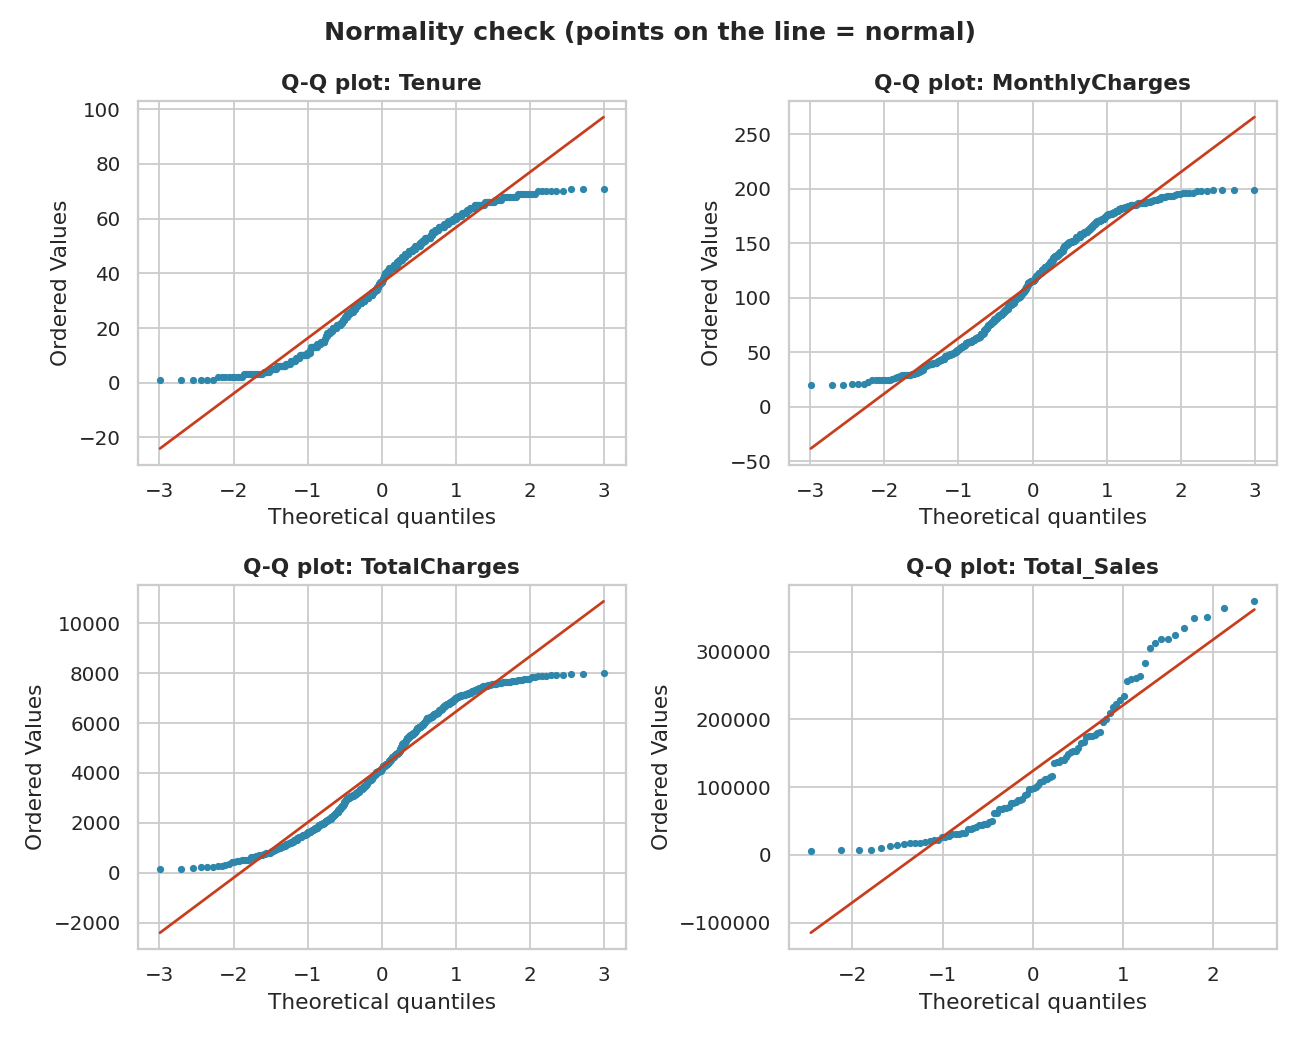

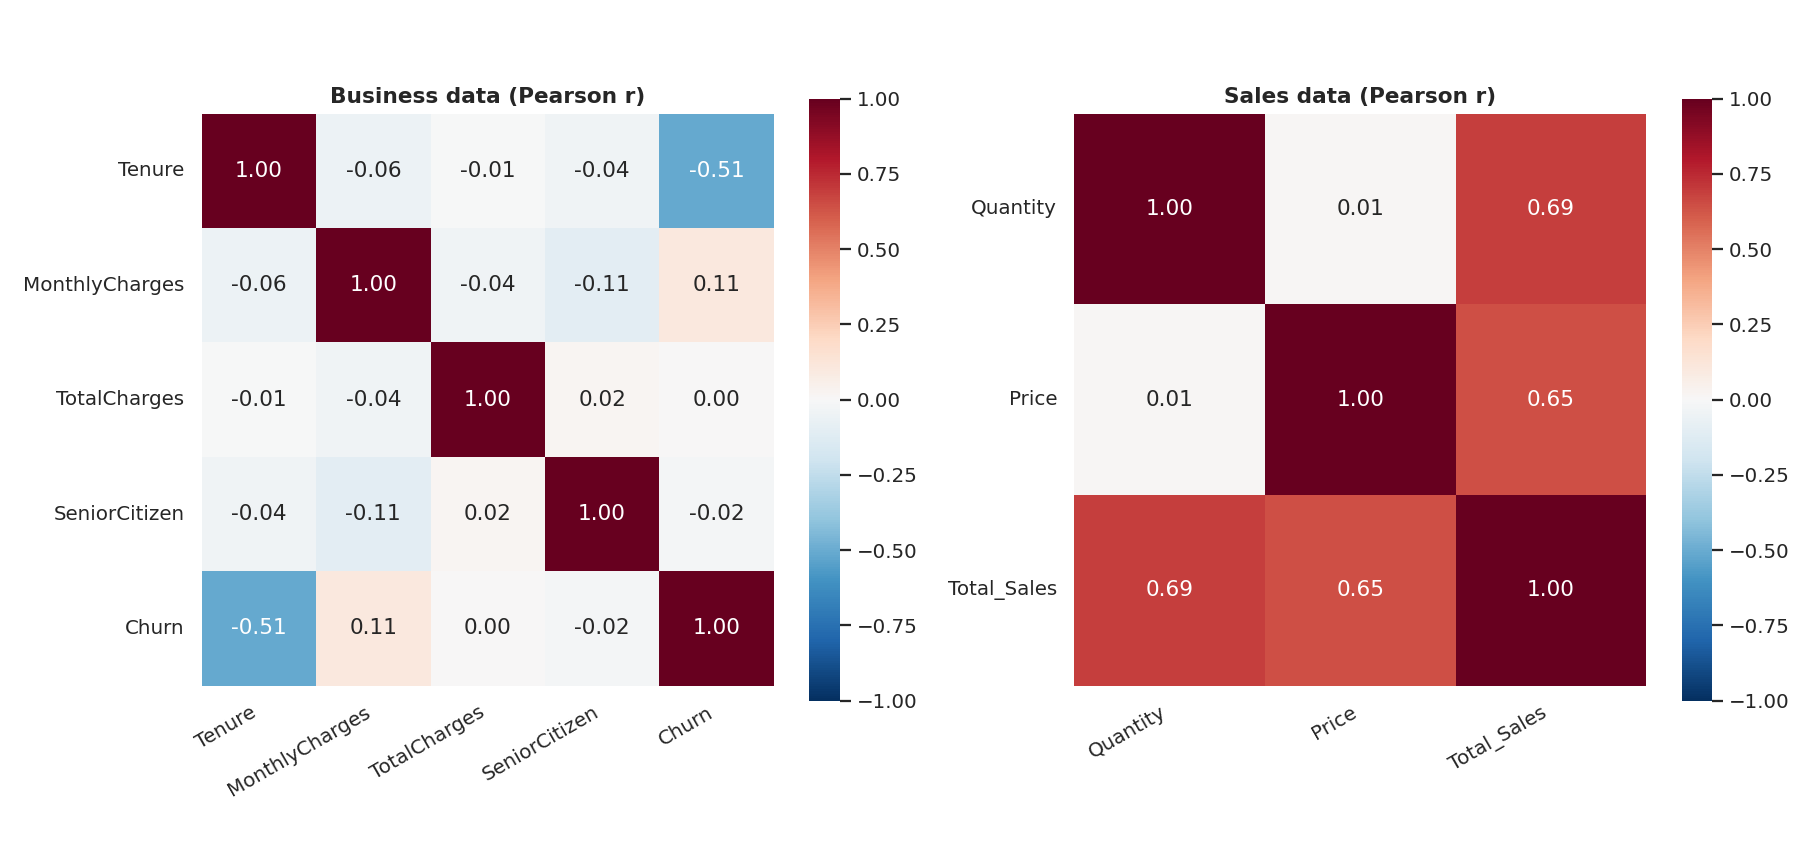

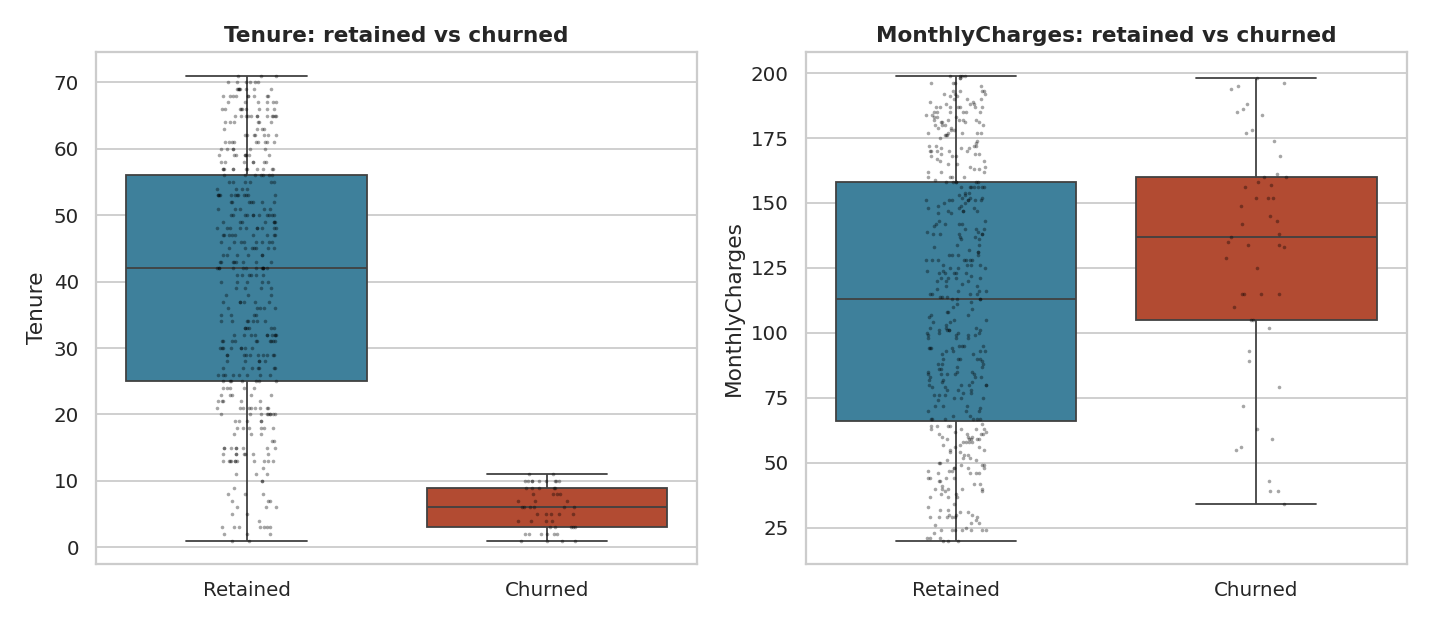

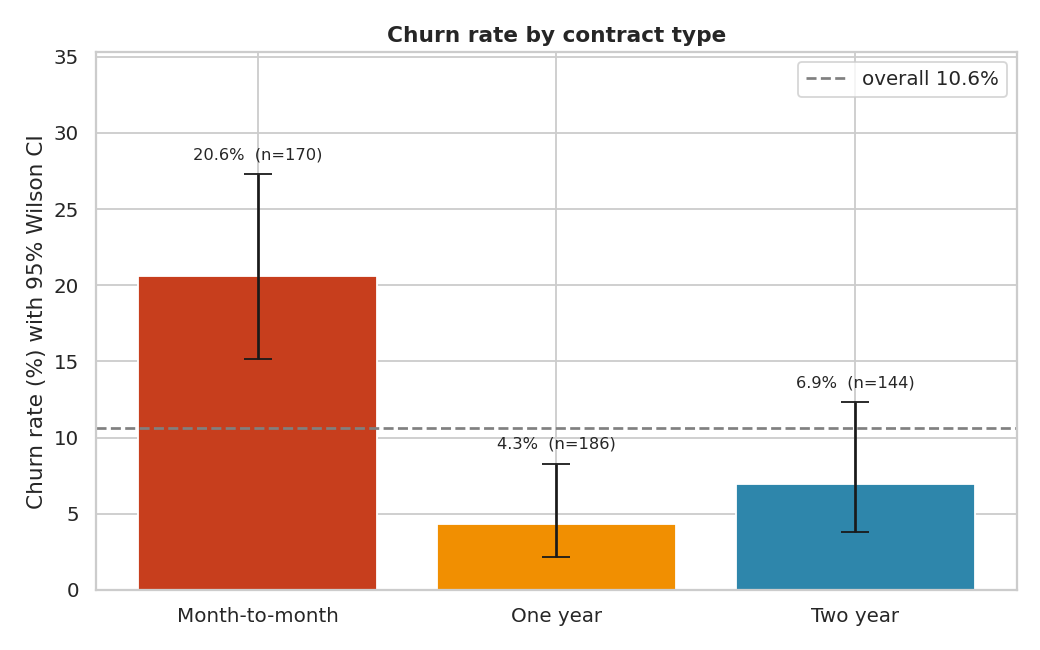

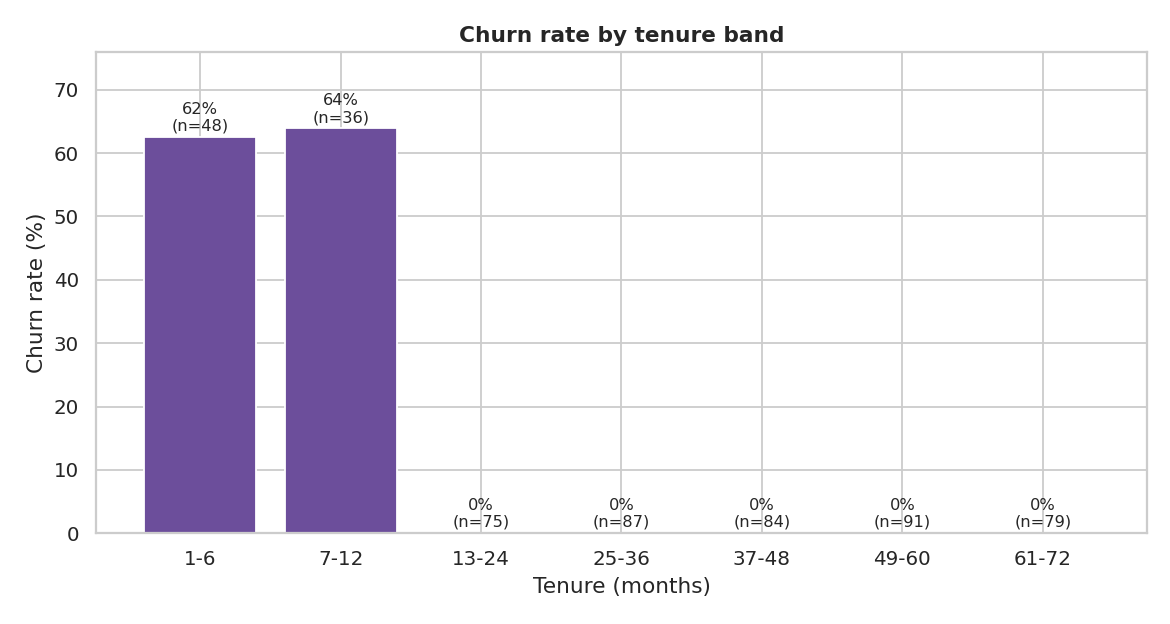

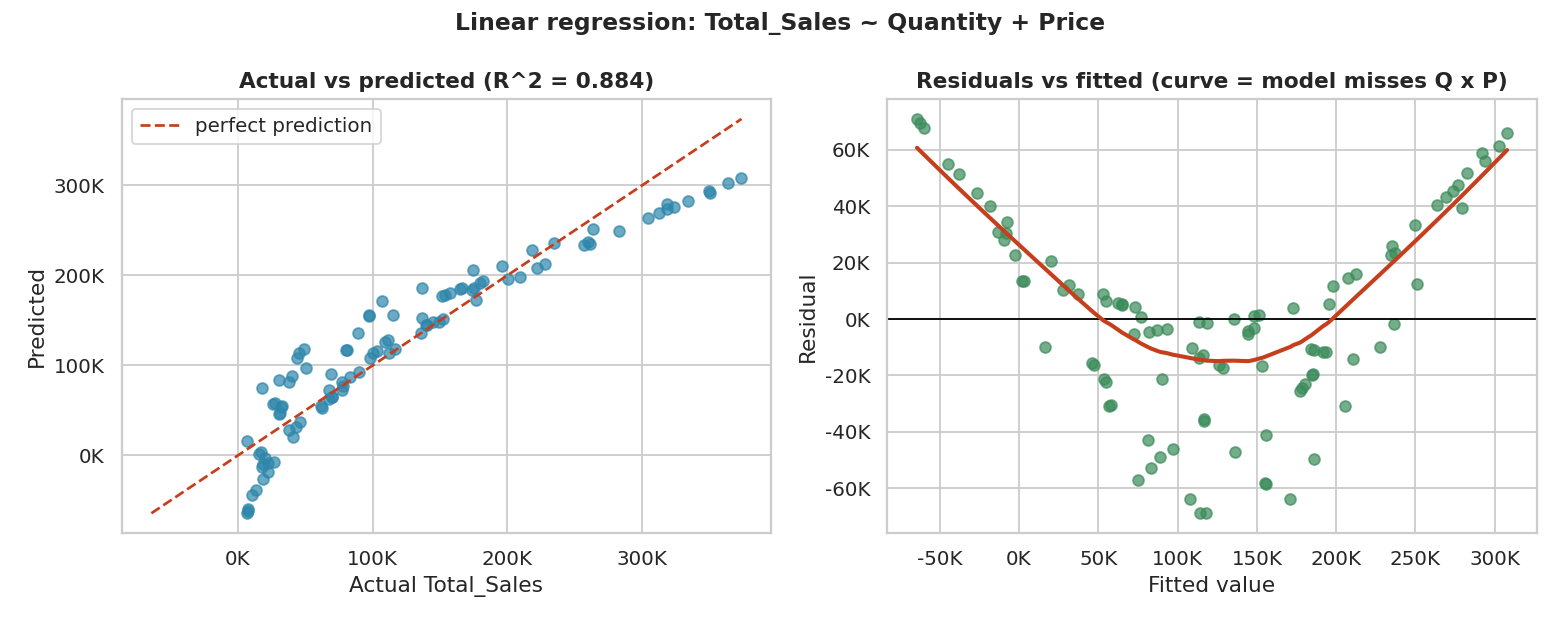

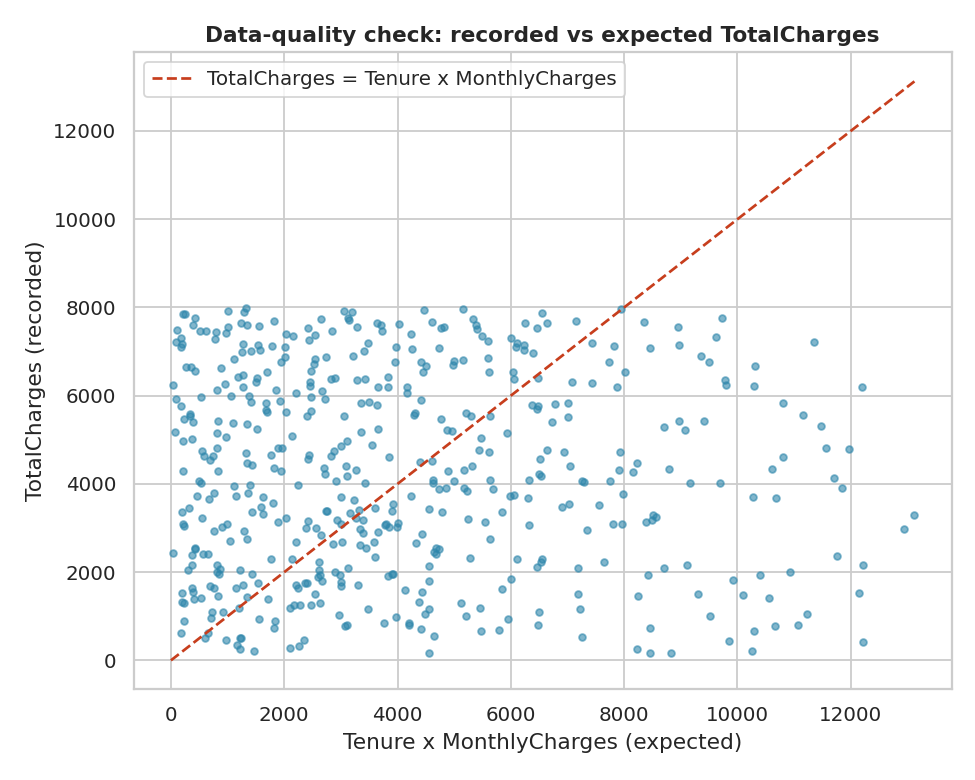

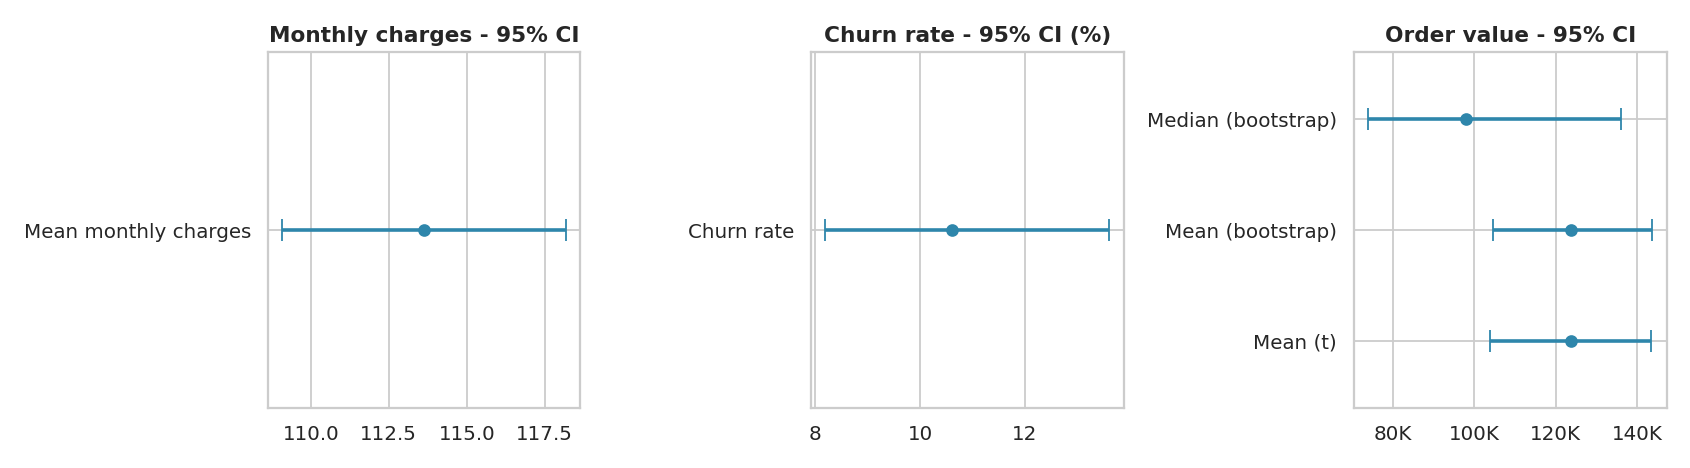

In [13]:
results = sa.run_analysis()
for chart in results["charts"]:
    display(Image(filename=str(chart)))

## 8. Business insights and recommendations

In [14]:
print("INSIGHTS")
for i, text in enumerate(results["insights"], 1):
    print(f"{i}. {text}")
print("\nRECOMMENDATIONS")
for text in results["recommendations"]:
    print(f"- {text}")

INSIGHTS
1. Tenure is the strongest churn signal: churned customers averaged 6.0 months vs 40.2 for retained (p = 8.98e-130, Cohen's d = -1.92). Every churned customer left within 11 months.
2. Contract type matters (chi-square p = 9.59e-07, Cramer's V = 0.24). Among customers with 12 months or less, 35 of 35 month-to-month customers churned.
3. Churned customers paid more per month (129.8 vs 111.7, p = 0.0101, Cohen's d = 0.35), a small effect that does not survive a Bonferroni correction for 6 tests.
4. Payment method (p = 0.1445) and contract-level pricing (p = 0.9692) show no significant relationship, so neither is a churn lever on this evidence.
5. The overall churn rate is 10.6% (95% CI 8.2%-13.6%).
6. Order value is driven by Quantity and Price (R^2 = 0.884); product category alone does not significantly change order value (ANOVA p = 0.0934).
7. Data-quality issue: only 6.4% of customers have TotalCharges within 10% of Tenure x MonthlyCharges (correlation -0.037), so TotalCharge

## Limitations
- Observational data: results show association, not causation.
- Only 53 churned customers, so estimates about churners are less precise.
- Some patterns are unusually clean (no churn after 11 months; every short-tenure month-to-month customer churned), which suggests the dataset may be simulated - validate on real data before acting.
- No marketing-spend data, so marketing effectiveness could not be tested.
- The sales data covers only about 3 months and 100 orders.